# Section 8 · Operate with OpenQASM

Exam weight: 6% of C1000-179 · about 4 of the 68 questions

Official objectives
- 8.1 Structure types in OpenQASM 3 programs
- 8.2 Interpret OpenQASM semantics
- 8.3 Interoperate different versions of OpenQASM with Qiskit
- 8.4 Interact with the Qiskit IBM Runtime REST API

Topics
- read and write the skeleton of an OpenQASM 3 program: version, includes, declarations, gates, measurement, control flow, subroutines and timing;
- name the OpenQASM 3 classical types (`bit`, `int`, `uint`, `float`, `angle`, `bool`, `complex`, `duration`, `stretch`, arrays, `const`) and apply the casting rules;
- predict what a short OpenQASM program does (inclusive ranges, bit order, gate modifiers, conditions);
- convert circuits between Qiskit and OpenQASM 2 or 3 in both directions, and say what is lost or rejected;
- submit a Sampler or Estimator job through the REST API: IAM token, headers, request body, status and results.

Built from the Qiskit Advocate KR study notebooks `1_Structure_Types_QASM_KR.ipynb`, `2_and_3_Interoperate_QASM_QISKIT_KR.ipynb` and `4_Use_Qiskit_REST_API_ko.ipynb` and the QAMP 2025 tutorial (links in the Sources cell at the end).

Everything runs offline. The REST calls are real `requests` code, executed only when an API key is present (`if API_KEY:`).

In [1]:
import io, os, json, math, tempfile, warnings, contextlib
from collections import Counter

import numpy as np
import requests
import openqasm3
import qiskit, qiskit_qasm3_import
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, qasm2, qasm3
from qiskit.circuit import Parameter
from qiskit.primitives import BitArray
from qiskit.quantum_info import Operator, SparsePauliOp
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime import SamplerV2
from qiskit_ibm_runtime.fake_provider import FakeFez

print(f"qiskit {qiskit.__version__} | qiskit-qasm3-import {qiskit_qasm3_import.__version__} "
      f"| openqasm3 (reference parser) {openqasm3.__version__}")

sampler = SamplerV2(mode=AerSimulator())          # AerSimulator also runs dynamic circuits (if / else)
sampler.options.simulator.seed_simulator = 2026

def counts_of(qc, shots=100):
    # run one circuit with the Sampler and return the counts of all its classical bits
    return sampler.run([qc], shots=shots).result()[0].join_data().get_counts()

def check_syntax(src):
    """Parse with the OpenQASM 3 reference parser (syntax only, no type checking)."""
    buf = io.StringIO()
    try:
        with contextlib.redirect_stderr(buf):
            openqasm3.parse(src)
        return "valid syntax"
    except Exception as err:
        lines = (str(err) or buf.getvalue()).strip().splitlines()
        return f"{type(err).__name__}" + (f": {lines[0]}" if lines else "")

qiskit 2.0.3 | qiskit-qasm3-import 0.6.0 | openqasm3 (reference parser) 1.0.1


## 8.1 Structure and types of an OpenQASM 3 program

OpenQASM is an imperative language for quantum circuits plus real-time classical computation. It is the exchange format between tools and the circuit format of the Qiskit Runtime REST API. Version 3 added classical types, control flow, gate modifiers, timing and subroutines to the gate-list language of version 2.

### 8.1.1 Anatomy of a program

```text
OPENQASM 3.0;                  // version: first non-comment line, optional, "OPENQASM 3;" also valid
include "stdgates.inc";        // standard gates (h, x, cx, rz, sx, ...); only U and gphase are built in

input float[64] theta;         // value supplied at run time (Qiskit: a Parameter)
qubit[3] q;                    // quantum register     (OpenQASM 2: qreg q[3];)
bit[3] c;                      // classical register   (OpenQASM 2: creg c[3];)

gate zz_phase(a) x, y {        // gate definition: only gate calls inside the body
  cx x, y;
  rz(a) y;
  cx x, y;
}

h q[0];                        // statements end with ';'
cx q[0], q[1];
zz_phase(theta) q[1], q[2];
barrier q;                     // a gate on a register broadcasts over its qubits
c[0] = measure q[0];           // OpenQASM 2 form "measure q[0] -> c[0];" is still accepted
if (c[0]) {                    // real-time classical control (dynamic circuit)
  x q[2];
}
c[1:2] = measure q[1:2];       // ranges include both ends: bits 1 AND 2
```

Qiskit loads this program into a `QuantumCircuit`: the `input` becomes a `Parameter`, the `gate` a custom instruction and the `if` block an `if_else` operation.

qubits: 3 | clbits: 3 | parameters: [Parameter(theta)]
operations: {'measure': 3, 'h': 1, 'cx': 1, 'zz_phase': 1, 'barrier': 1, 'if_else': 1}


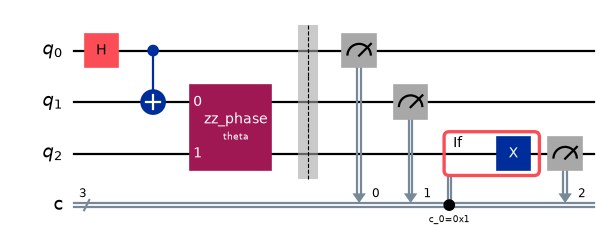

In [2]:
anatomy = '''
OPENQASM 3.0;
include "stdgates.inc";
input float[64] theta;
qubit[3] q;
bit[3] c;
gate zz_phase(a) x, y {
  cx x, y;
  rz(a) y;
  cx x, y;
}
h q[0];
cx q[0], q[1];
zz_phase(theta) q[1], q[2];
barrier q;
c[0] = measure q[0];
if (c[0]) {
  x q[2];
}
c[1:2] = measure q[1:2];
'''
anatomy_qc = qasm3.loads(anatomy)
print("qubits:", anatomy_qc.num_qubits, "| clbits:", anatomy_qc.num_clbits, "| parameters:", list(anatomy_qc.parameters))
print("operations:", dict(anatomy_qc.count_ops()))
anatomy_qc.draw("mpl", fold=-1, scale=0.8)

| Rule | Detail |
|---|---|
| Version | `OPENQASM 3.0;` or `OPENQASM 3;` as the first non-comment line (optional in OpenQASM 3, at most once; required in OpenQASM 2) |
| Includes | `include "stdgates.inc";` at global scope. OpenQASM 2 used `qelib1.inc` |
| Built-in gates | OpenQASM 3: only `U(θ, φ, λ)` and `gphase(γ)`. OpenQASM 2: `U` and `CX`. Everything else (`cx`, `h`, `CX` for compatibility, ...) comes from `stdgates.inc` |
| Qubits | `qubit q;`, `qubit[n] q;` (global scope only); hardware qubits `$0, $1, ...` are used without declaration. `qreg` is kept only for backwards compatibility |
| Classical bits | `bit c;`, `bit[n] c;`; `creg` is kept only for backwards compatibility |
| Measurement | `c = measure q;` or `c[0] = measure q[0];`; the old `measure q -> c;` is still valid |
| Gate bodies | only built-in gates and previously defined gates; no measurement, reset or classical declarations |
| Comments | `// line` and `/* block */` |

Caution when copying the cat-state example on the Introduction to OpenQASM docs page: it writes an untyped `const n = 3;` and the gate `cnot`, which the reference parser and `stdgates.inc` do not accept (use `const uint n = 3;` and `cx`).

If a question shows `include "qelib1.inc"`, `qreg`/`creg` and `measure q -> c;` with `OPENQASM 2.0;`, it is OpenQASM 2. `stdgates.inc`, `qubit`/`bit`, `c = measure q;`, `input`, `if (...) { }` blocks and `$0` qubits are OpenQASM 3.

### 8.1.2 Classical types

| Type | Syntax examples | Notes |
|---|---|---|
| bit / bit register | `bit b;` `bit[8] r = "0000_1111";` | little-endian: `r[0]` is the least significant bit |
| signed integer | `int[16] i = -3;` `int n;` | without a width the precision is set by the target architecture |
| unsigned integer | `uint[8] u = 0x1F;` | literals: `0b1010`, `0o17`, `0xFF`, `1_000` |
| floating point | `float[64] x = 2.5e-1;` `float f;` | IEEE 754 (`float[64]` is double precision) |
| angle | `angle[8] phi = pi / 4;` | fixed point on $[0, 2\pi)$, arithmetic wraps modulo $2\pi$ |
| boolean | `bool done = false;` | `true` / `false` |
| complex | `complex[float[64]] z = 1.5 + 2.0im;` | imaginary literal ends in `im`; `real(z)`, `imag(z)` |
| duration | `duration d = 100ns;` | units `ns`, `us`/`µs`, `ms`, `s`, `dt` (device cycles) |
| stretch | `stretch s;` | a duration resolved by the compiler (used to align timing) |
| array | `array[int[8], 3] a = {1, 2, 3};` | up to 7 dimensions, global scope only; no `bit` base type |
| constant | `const uint N = 4;` `qubit[N] q;` | compile-time; needed wherever a width or size is required |
| I/O | `input float[64] theta;` `output bit[2] res;` | `input`: supplied at run time; if nothing is marked `output`, all variables are outputs |

Built-in constants: `pi`/`π`, `tau`/`τ`, `euler`/`ℇ`. Built-in functions for constant expressions include `sin`, `cos`, `tan`, `arcsin`, `arccos`, `arctan`, `exp`, `log`, `sqrt`, `mod`, `pow`, `floor`, `ceiling`, `popcount`, `rotl`, `rotr`, `real`, `imag`.

The reference parser `openqasm3` (installed with `qiskit-qasm3-import`) checks syntax and shows how each declaration is typed:

In [3]:
types_program = '''
OPENQASM 3.0;
include "stdgates.inc";
const uint N = 4;
qubit[N] q;
bit[N] c;
int[16] offset = -3;
uint[8] count = 0x1F;
float[64] ratio = 2.5e-1;
angle[8] phi = pi / 4;
bool done = false;
complex[float[64]] z = 1.5 + 2.0im;
duration wait = 100ns;
stretch s;
array[int[8], 3] table = {1, 2, 3};
input float[64] theta;
output bit[2] result;
'''
for stmt in openqasm3.parse(types_program).statements:
    if hasattr(stmt, "identifier") and hasattr(stmt, "type"):
        print(f"{type(stmt).__name__:22s} {stmt.identifier.name:8s} -> {type(stmt.type).__name__}")

ConstantDeclaration    N        -> UintType
ClassicalDeclaration   c        -> BitType
ClassicalDeclaration   offset   -> IntType
ClassicalDeclaration   count    -> UintType
ClassicalDeclaration   ratio    -> FloatType
ClassicalDeclaration   phi      -> AngleType
ClassicalDeclaration   done     -> BoolType
ClassicalDeclaration   z        -> ComplexType
ClassicalDeclaration   wait     -> DurationType
ClassicalDeclaration   s        -> StretchType
ClassicalDeclaration   table    -> ArrayType
IODeclaration          theta    -> FloatType
IODeclaration          result   -> BitType


In [4]:
for label, src in {
    "complex with im suffix": "OPENQASM 3.0; complex[float[64]] z = 1.0 + 2.0im;",
    "complex with Python j ": "OPENQASM 3.0; complex[float[64]] z = 1.0 + 2.0j;",
    "type name 'double'    ": "OPENQASM 3.0; double x = 1.5;",
    "untyped const         ": "OPENQASM 3.0; const n = 3;",
    "array inside a def    ": "OPENQASM 3.0; def f() { array[int[8], 2] a = {1, 2}; }",
}.items():
    print(f"{label}: {check_syntax(src)}")

complex with im suffix: valid syntax
complex with Python j : QASM3ParsingError
type name 'double'    : QASM3ParsingError
untyped const         : QASM3ParsingError: line 1:20 no viable alternative at input 'n'
array inside a def    : QASM3ParsingError: L1:C24: arrays can only be declared globally


The parser only checks syntax. Semantic rules such as "a width must be a compile-time constant" (`uint n = 4; qubit[n] q;` is invalid because `n` is not `const`) or "12 does not fit in `int[4]`" (range $-8 \dots 7$) are enforced by compilers, not by this grammar check.

### 8.1.3 Casting rules

Explicit casts use the target type as a function: `int[8](x)`, `bool(b)`, `bit[4](u)`. Allowed conversions (from the OpenQASM 3 specification; row = from, column = to):

| from \\ to | bool | int | uint | float | angle | bit | duration |
|---|---|---|---|---|---|---|---|
| bool | - | yes | yes | yes | no | yes | no |
| int | yes | - | yes | yes | no | yes | no |
| uint | yes | yes | - | yes | no | yes | no |
| float | yes | yes | yes | - | yes | no | no |
| angle | yes | no | no | no | - | yes | no |
| bit | yes | yes | yes | no | yes | - | no |
| duration | no | no | no | only via `duration / duration` | no | no | - |

`qubit` never casts to or from anything. The rules behind the table:

- `bool`: `false` → `0` / `0.0`, `true` → `1` / `1.0`; anything → `bool` means `value != 0`.
- `int[n]` ↔ `uint[n]`: the bit pattern is kept (two's complement), so `"1111"` is 15 as `uint[4]` and $-1$ as `int[4]`.
- `bit[n]` ↔ `int[m]`, `uint[m]`, `angle[m]`: only when $n = m$; little-endian bit copy.
- `float` → `int`/`uint`: the fractional part is discarded (C99), so `int(2.7)` is 2 and `int(-2.7)` is $-2$.
- `float` → `angle[n]`: nearest multiple of $2\pi/2^n$, taken modulo $2\pi$ (ties to even).
- Mixed binary operations promote the lesser type: `complex` > `float` > `int`/`uint`, and within a family the wider type wins.

`angle[n]` in one line. An `angle[n]` stores an $n$-bit unsigned integer $k$ and means $\theta = 2\pi k / 2^n$. The most significant bit is worth $\pi$, so $\pi$ in `angle[4]` is `1000` and $\pi/2$ is `0100`. Adding angles is unsigned addition with overflow, which is exactly arithmetic modulo $2\pi$.

In [5]:
def angle_bits(theta, n):
    """Python model of float -> angle[n]: bit string of the nearest representable angle (mod 2π)."""
    k = round(theta / (2 * math.pi) * 2**n) % 2**n      # Python's round() is round-half-to-even
    return format(k, f"0{n}b")

for theta, label in [(math.pi, "π"), (math.pi / 2, "π/2"), (7 * math.pi / 8, "7π/8"),
                     (-math.pi / 4, "-π/4"), (2 * math.pi, "2π")]:
    print(f"angle[4] = {label:5s} -> {angle_bits(theta, 4)}")

# int[4] and uint[4] read the same bit pattern differently (two's complement)
pattern = 0b1111
print("bit[4] '1111' as uint[4]:", pattern, "| as int[4]:", pattern - 16 if pattern & 0b1000 else pattern)
print("float -> int drops the fraction:", int(2.7), int(-2.7))

angle[4] = π     -> 1000
angle[4] = π/2   -> 0100
angle[4] = 7π/8  -> 0111
angle[4] = -π/4  -> 1110
angle[4] = 2π    -> 0000
bit[4] '1111' as uint[4]: 15 | as int[4]: -1
float -> int drops the fraction: 2 -2


### Practice 8.1 — Encode an angle

Write `ex1_angle_bits(theta, n)` that returns the `n`-character bit string OpenQASM stores for `angle[n] = theta` (nearest representable value, taken modulo $2\pi$). Do not call the lecture helper `angle_bits`.

In [ ]:
def ex1_angle_bits(theta, n):
    return None   # TODO

In [ ]:
# Run this cell to check your answer
assert ex1_angle_bits(math.pi, 4) == "1000"
assert ex1_angle_bits(math.pi / 2, 6) == "010000"
assert ex1_angle_bits(7 * math.pi / 8, 8) == "01110000"
assert ex1_angle_bits(-math.pi / 4, 4) == "1110", "negative angles wrap modulo 2π"
assert ex1_angle_bits(3 * math.pi, 3) == "100", "3π wraps to π"
print("Correct!")

<details>
<summary>Show solution</summary>

```python
def ex1_angle_bits(theta, n):
    k = round(theta / (2 * math.pi) * 2**n) % 2**n
    return format(k, f"0{n}b")
```

One step is $2\pi/2^n$, so $\theta$ corresponds to $k = \theta\,2^n/(2\pi)$ steps; `% 2**n` implements the wrap-around ($-\pi/4 \to 7\pi/4 \to 14$ steps of $\pi/8$ = `1110`). The leading bit is worth $\pi$, the next $\pi/2$, and so on.

</details>

### Practice 8.2 — Write an OpenQASM 3 program

Write `ex2_program`, an OpenQASM 3 string that

1. declares a run-time parameter `theta` of type `float[64]`,
2. declares a 2-qubit register `q` and a 2-bit register `c`,
3. applies `ry(theta)` to `q[0]`, then `cx` from `q[0]` to `q[1]`,
4. measures both qubits into `c`.

The check loads it with `qasm3.loads` and compares it with the equivalent Qiskit circuit.

In [ ]:
ex2_program = '''
OPENQASM 3.0;
include "stdgates.inc";
// TODO
'''

In [ ]:
# Run this cell to check your answer
_qc = qasm3.loads(ex2_program)
assert _qc.num_qubits == 2 and _qc.num_clbits == 2
assert [p.name for p in _qc.parameters] == ["theta"], "declare: input float[64] theta;"
assert _qc.count_ops().get("measure", 0) == 2
_ref = QuantumCircuit(2); _t = Parameter("theta"); _ref.ry(_t, 0); _ref.cx(0, 1)
_mine = _qc.remove_final_measurements(inplace=False)
assert Operator(_mine.assign_parameters([0.7])).equiv(Operator(_ref.assign_parameters([0.7])))
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex2_program = '''
OPENQASM 3.0;
include "stdgates.inc";
input float[64] theta;
qubit[2] q;
bit[2] c;
ry(theta) q[0];
cx q[0], q[1];
c = measure q;
'''
```

`input float[64] theta;` is how OpenQASM 3 exposes a run-time parameter; Qiskit turns it into a `Parameter` (and the exporter writes every unbound `Parameter` this way). `c = measure q;` measures the register element by element, `c[i]` from `q[i]`.

</details>

Q8.1. Which line is a valid OpenQASM 3 declaration?

A. `complex z = 1 + 2j;`

B. `double x = 1.5;`

C. `string label = "run1";`

D. `complex[float[64]] z = 1.0 + 2.0im;`

<details>
<summary>Show answer</summary>

Answer: D

OpenQASM 3 has a `complex` type whose component type is a `float`, and imaginary literals end in `im`. The Python suffix `j` (A) is a syntax error; `double` (B) and `string` (C) are not OpenQASM types (use `float[64]`; there is no string type).

</details>

Q8.2. Which two explicit casts are not allowed in OpenQASM 3? (Select two.)

A. `float[64]` to `bit[8]`

B. `int[32]` to `float[64]`

C. `bit` to `bool`

D. `angle[8]` to `int[8]`

E. `bool` to `uint[8]`

<details>
<summary>Show answer</summary>

Answer: A, D

The casting table forbids `float` to `bit` and `angle` to `int`/`uint`/`float`: an angle is a point on the circle, not a number, so you can only reinterpret its bits (`angle[n]` to `bit[n]`) or test it against zero (`bool`). Integer to float, bit to bool and bool to integer are all allowed.

</details>

## 8.2 Interpret OpenQASM semantics

Exam questions show a few lines of OpenQASM and ask what happens. Four rules decide most of them.

### 8.2.1 Indexing: inclusive ranges, index sets, negative indices, aliases

| Syntax | Selects |
|---|---|
| `q[1:3]` | `q[1], q[2], q[3]` (both ends included) |
| `q[0:2:6]` | start 0, step 2, stop 6: `q[0], q[2], q[4], q[6]` |
| `q[{0, 3}]` | `q[0]` and `q[3]` |
| `q[-1]` | last element |
| `let r = q[1:3];` | an alias (a reference, not a copy) |
| `let ab = a ++ b;` | concatenation of two registers |
| `for uint i in [0:3] { ... }` | runs for `i = 0, 1, 2, 3` (four times) |

Qiskit's importer applies the same rules:

In [6]:
H = 'OPENQASM 3.0;\ninclude "stdgates.inc";\n'

def x_targets(body, n):
    """Load a small program and list the qubit indices that receive an x gate."""
    qc = qasm3.loads(H + f"qubit[{n}] q;\n" + body)
    return [qc.find_bit(inst.qubits[0]).index for inst in qc.data if inst.operation.name == "x"]

print("x q[1:3];                 ->", x_targets("x q[1:3];", 5))
print("x q[0:2:4];               ->", x_targets("x q[0:2:4];", 5))
print("x q[{0, 3}];              ->", x_targets("x q[{0, 3}];", 5))
print("x q[-1];                  ->", x_targets("x q[-1];", 5))
print("let r = q[2:3]; x r[0];   ->", x_targets("let r = q[2:3]; x r[0];", 5))

loop_qc = qasm3.loads(H + "qubit q; for uint i in [0:3] { x q; }")
print("for uint i in [0:3] iterates over", list(loop_qc.data[0].operation.params[0]))

x q[1:3];                 -> [1, 2, 3]
x q[0:2:4];               -> [0, 2, 4]
x q[{0, 3}];              -> [0, 3]
x q[-1];                  -> [4]
let r = q[2:3]; x r[0];   -> [2]
for uint i in [0:3] iterates over [0, 1, 2, 3]


Python slices exclude the stop value; OpenQASM ranges include it. `q[1:3]` is three qubits, and `for uint i in [0:n-1]` already covers `n` iterations; writing `[0:n]` runs one extra time.

### 8.2.2 Registers as integers and conditions

A `bit[n]` register compared with an integer is read little-endian: `c[0]` is worth 1, `c[1]` is worth 2, and so on. Qiskit prints counts in the same order (`c[n-1] ... c[0]`).

| Condition | True when |
|---|---|
| `if (c[0]) { ... }` | bit 0 is 1 |
| `if (c == 2) { ... }` | `c[1] = 1` and every other bit is 0 |
| `if (c[0] == true) { ... }` | bit 0 is 1 (the Qiskit importer wants `true`/`false`, not `1`, when comparing a single bit) |
| `while (c[0] == false) { ... }` | repeat until bit 0 reads 1 |

Run a dynamic program with `SamplerV2` on `AerSimulator` to see it:

In [7]:
cond_program = H + '''
qubit[3] q;
bit[3] c;
x q[1];
c = measure q;          // c = "010", the integer 2
if (c == 2) {
  x q[2];
}
c = measure q;
'''
cond_qc = qasm3.loads(cond_program)
print(counts_of(cond_qc, shots=100))

{'110': 100}


### 8.2.3 Gate modifiers and built-in gates

| Modifier | Meaning | Argument order |
|---|---|---|
| `ctrl @ g` | controlled-`g` (control on $\vert 1\rangle$) | control qubit first, then the targets of `g` |
| `negctrl @ g` | controlled-`g`, control on $\vert 0\rangle$ | control first |
| `ctrl(2) @ g` | two controls | both controls first |
| `inv @ g` | $g^\dagger$ | as for `g` |
| `pow(k) @ g` | $g^k$ | as for `g` |

`U(θ, φ, λ)` is the only built-in one-qubit gate and `gphase(γ)` the built-in global phase. The Qiskit importer evaluates modifiers while parsing, so the loaded circuit contains ordinary gates:

In [8]:
for body in ["ctrl @ x q[0], q[1];", "negctrl @ x q[0], q[1];", "ctrl(2) @ x q[0], q[1], q[2];",
             "inv @ s q[0];", "pow(2) @ s q[0];", "gphase(pi / 2);"]:
    qc = qasm3.loads(H + "qubit[3] q;\n" + body)
    ops = [(i.operation.name, [qc.find_bit(b).index for b in i.qubits]) for i in qc.data]
    print(f"{body:32s} -> {ops}  global phase = {qc.global_phase:.4f}")

print("pow(2) @ s is Z:", Operator(qasm3.loads(H + "qubit q; pow(2) @ s q;")).equiv(Operator.from_label("Z")))
neg_qc = qasm3.loads(H + "qubit[2] q; bit[2] c; negctrl @ x q[0], q[1]; c = measure q;")
print("negctrl @ x on |00>:", counts_of(neg_qc, shots=50))

ctrl @ x q[0], q[1];             -> [('cx', [0, 1])]  global phase = 0.0000
negctrl @ x q[0], q[1];          -> [('cx_o0', [0, 1])]  global phase = 0.0000
ctrl(2) @ x q[0], q[1], q[2];    -> [('ccx', [0, 1, 2])]  global phase = 0.0000
inv @ s q[0];                    -> [('sdg', [0])]  global phase = 0.0000
pow(2) @ s q[0];                 -> [('p', [0])]  global phase = 0.0000
gphase(pi / 2);                  -> []  global phase = 1.5708
pow(2) @ s is Z: True
negctrl @ x on |00>: {'10': 50}


Read a modifier chain from left to right: every `ctrl @` or `negctrl @` takes the next qubit argument as a control, and the remaining gate acts on what is left. `negctrl @ ctrl @ x q[2], q[0], q[1];` flips `q[1]` when `q[2]` is 0 and `q[0]` is 1; `ctrl @ inv @ s q[0], q[1];` is a controlled $S^\dagger$ with control `q[0]`.

### 8.2.4 Loops, subroutines, timing and calibrations

```text
for uint i in [0:2] { rx(0.1) q[0]; }        // 3 iterations
for int k in {1, 5, 10} { ... }             // discrete set
while (c[0] == false) { h q[0]; c[0] = measure q[0]; }
switch (i) { case 0 { x q[0]; } case 1, 2 { z q[0]; } default { } }

def parity(bit[2] b) -> bit { return b[0] ^ b[1]; }    // subroutine (classical and quantum args)
extern get_angle(int[32]) -> angle[32];                 // implemented outside the program

delay[100ns] q[0];                  // idle time; units ns, us, ms, s, dt
box [1us] { x q[0]; }               // group operations, optionally with a duration
barrier q;                          // no reordering across this line

defcalgrammar "openpulse";          // pulse-level calibrations (defcal): know that they exist
```

Qiskit can represent and export `for`, `while`, `switch`, `if`/`else`, `delay`, `box` and `barrier`. The Qiskit importer (qiskit-qasm3-import 0.6) rejects classical declarations (`int`, `float`, `bool`, `angle`, `complex`, `duration`, `const`), every `switch` statement, `def`, `extern`, `output` and `defcal`. Qiskit 2.0 removed the `qiskit.pulse` module, so pulse calibrations are outside the SDK.

### Practice 8.3 — Predict the outcome

Without running it, predict what this program measures. Store the bit string Qiskit would print in `ex3_bitstring` and the integer value of the register `c` in `ex3_value`.

```text
OPENQASM 3.0;
include "stdgates.inc";
qubit[4] q;
bit[4] c;
x q[1:2];
negctrl @ x q[0], q[3];
inv @ s q[1];
c = measure q;
```

In [ ]:
ex3_bitstring = None   # TODO, e.g. "0101"
ex3_value = None       # TODO, an int

In [ ]:
# Run this cell to check your answer
_prog = H + "qubit[4] q; bit[4] c; x q[1:2]; negctrl @ x q[0], q[3]; inv @ s q[1]; c = measure q;"
_counts = counts_of(qasm3.loads(_prog), shots=20)
assert isinstance(ex3_bitstring, str) and len(ex3_bitstring) == 4, "a 4-character bit string"
assert list(_counts) == [ex3_bitstring], "that is not what the program measures"
assert ex3_value == int(ex3_bitstring, 2)
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex3_bitstring = "1110"   # q0 = 0, q1 = 1, q2 = 1, q3 flipped because q0 is 0
ex3_value = 14
```

`x q[1:2]` flips two qubits (inclusive range). `negctrl @ x q[0], q[3]` flips `q[3]` because `q[0]` is $|0\rangle$. `inv @ s` only adds a phase. Reading `c[3] c[2] c[1] c[0]` gives `1110` = 14. The two tempting mistakes are `0010` (exclusive range and `ctrl` instead of `negctrl`) and `0111` (big-endian reading).

</details>

Q8.3. What is measured?

```text
OPENQASM 3.0;
include "stdgates.inc";
qubit[2] q;
bit[2] c;
x q[0];
c = measure q;
if (c == 1) {
  x q[1];
}
c = measure q;
```

A. `01` (the `if` body never runs)

B. `10`

C. `00`

D. `11`

<details>
<summary>Show answer</summary>

Answer: D

After `x q[0]` the first measurement gives `c[0] = 1`, `c[1] = 0`, which is the integer 1, so the condition holds and `x q[1]` runs. The second measurement gives `11`. Answer A comes from reading `c == 1` as "bit 1 is set".

</details>

Q8.4. How many `h` gates act on `q` when this loop runs, and what is the final state of `q` (starting from $|0\rangle$)?

```text
for uint i in [0:3] {
  h q;
}
```

A. 3 gates; $|+\rangle$

B. 4 gates; $|0\rangle$

C. 3 gates; $|0\rangle$

D. 4 gates; $|+\rangle$

<details>
<summary>Show answer</summary>

Answer: B

The range `[0:3]` includes 3, so the body runs for `i = 0, 1, 2, 3`: four Hadamards, and $H^4 = I$. Three gates (A) is the Python-slice reading of the range.

</details>

## 8.3 Interoperate OpenQASM 2 and 3 with Qiskit

### 8.3.1 OpenQASM 2 versus OpenQASM 3

| Feature | OpenQASM 2 | OpenQASM 3 |
|---|---|---|
| Header / library | `OPENQASM 2.0;` `include "qelib1.inc";` | `OPENQASM 3.0;` `include "stdgates.inc";` |
| Registers | `qreg q[2]; creg c[2];` | `qubit[2] q; bit[2] c;` (`qreg`/`creg` still parse) |
| Measurement | `measure q -> c;` | `c = measure q;` (arrow form still valid) |
| Built-in gates | `U`, `CX` | `U`, `gphase` |
| Classical control | only `if (creg == int) single_op;` | `if`/`else`, `while`, `for`, `switch`, expressions, `break`/`continue` |
| Classical data | bit registers only | `int`, `uint`, `float`, `angle`, `bool`, `complex`, arrays, `const` |
| Parameters | numeric only | `input float[64] theta;` |
| Gate modifiers | none | `ctrl @`, `negctrl @`, `inv @`, `pow(k) @` |
| Timing | none | `delay`, `box`, `duration`, `stretch` |
| Subroutines, pulses | `opaque` gates | `def`, `extern`, `defcal` |
| Hardware qubits | none | `$0`, `$1`, ... |

### 8.3.2 The Qiskit functions

| | OpenQASM 2 (`qiskit.qasm2`) | OpenQASM 3 (`qiskit.qasm3`) |
|---|---|---|
| Circuit → string | `qasm2.dumps(qc)` | `qasm3.dumps(qc)` |
| Circuit → file | `qasm2.dump(qc, "f.qasm")` (path or open stream) | `qasm3.dump(qc, stream)` (an open file object) |
| String → circuit | `qasm2.loads(s)`, `QuantumCircuit.from_qasm_str(s)` | `qasm3.loads(s)` (needs `qiskit-qasm3-import`), `qasm3.loads_experimental(s)` |
| File → circuit | `qasm2.load(path)`, `QuantumCircuit.from_qasm_file(path)` | `qasm3.load(path)`, `qasm3.load_experimental(path)` |
| Errors | `QASM2ExportError`, `QASM2ParseError` | `QASM3ExporterError`, `QASM3ImporterError` |
| Options | `include_path`, `include_input_directory`, `custom_instructions`, `custom_classical`, `strict` | `qasm3.Exporter(includes, basis_gates, disable_constants, alias_classical_registers, allow_aliasing, indent, experimental)`; `qasm3.loads(program)` takes no options |

`QuantumCircuit.from_qasm_str` / `from_qasm_file` read OpenQASM 2 only and use the legacy settings described below. The old `qc.qasm()` method no longer exists.

In [9]:
bell = QuantumCircuit(2, 2, name="bell")
bell.h(0); bell.cx(0, 1); bell.measure([0, 1], [0, 1])

text2, text3 = qasm2.dumps(bell), qasm3.dumps(bell)
print(text2); print(text3)

same2 = qasm2.loads(text2) == bell
same3 = Operator(qasm3.loads(text3).remove_final_measurements(inplace=False)).equiv(
        Operator(bell.remove_final_measurements(inplace=False)))
print("OpenQASM 2 round trip identical:", same2, "| OpenQASM 3 round trip equivalent:", same3)

try:
    QuantumCircuit.from_qasm_str(text3)
except qasm2.QASM2ParseError as err:
    print("from_qasm_str on OpenQASM 3 ->", type(err).__name__, err)

OPENQASM 2.0;
include "qelib1.inc";
qreg q[2];
creg c[2];
h q[0];
cx q[0],q[1];
measure q[0] -> c[0];
measure q[1] -> c[1];
OPENQASM 3.0;
include "stdgates.inc";
bit[2] c;
qubit[2] q;
h q[0];
cx q[0], q[1];
c[0] = measure q[0];
c[1] = measure q[1];

OpenQASM 2 round trip identical: True | OpenQASM 3 round trip equivalent: True
from_qasm_str on OpenQASM 3 -> QASM2ParseError '<input>:1,9: can only handle OpenQASM 2.0, but given 3.0'


Files. The two `dump` functions differ in what they accept:

In [10]:
folder = tempfile.mkdtemp(prefix="sec8_")
qasm2.dump(bell, os.path.join(folder, "bell2.qasm"))              # a path is fine for OpenQASM 2

with open(os.path.join(folder, "bell3.qasm"), "w") as f:           # OpenQASM 3 needs an open stream
    qasm3.dump(bell, f)

try:
    qasm3.dump(bell, os.path.join(folder, "oops.qasm"))
except AttributeError as err:
    print("qasm3.dump(qc, 'path') ->", type(err).__name__, err)

print(qasm3.load(os.path.join(folder, "bell3.qasm")).count_ops(),
      QuantumCircuit.from_qasm_file(os.path.join(folder, "bell2.qasm")).count_ops())

qasm3.dump(qc, 'path') -> AttributeError 'str' object has no attribute 'write'
OrderedDict([('measure', 2), ('h', 1), ('cx', 1)]) OrderedDict([('measure', 2), ('h', 1), ('cx', 1)])


To write OpenQASM 3 to a file: `with open("circuit.qasm", "w") as f: qasm3.dump(qc, f)`. For a string use `qasm3.dumps(qc)` (one argument only). The `s` in `dumps`/`loads` means string, as in Python's `json` module.

### 8.3.3 What changes in translation

Parameters. OpenQASM 3 exports each unbound `Parameter` as `input float[64] name;` and the importer turns it back into a `Parameter`. OpenQASM 2 cannot represent free parameters.

In [11]:
theta = Parameter("theta")
param_qc = QuantumCircuit(1, 1)
param_qc.rx(theta, 0); param_qc.measure(0, 0)

print(qasm3.dumps(param_qc))
print("re-imported parameters:", list(qasm3.loads(qasm3.dumps(param_qc)).parameters))
try:
    qasm2.dumps(param_qc)
except qasm2.QASM2ExportError as err:
    print("qasm2:", err)
print(qasm2.dumps(param_qc.assign_parameters({theta: 0.25})).splitlines()[-2])

OPENQASM 3.0;
include "stdgates.inc";
input float[64] theta;
bit[1] c;
qubit[1] q;
rx(theta) q[0];
c[0] = measure q[0];

re-imported parameters: [Parameter(theta)]
qasm2: 'Cannot represent circuits with unbound parameters in OpenQASM 2.'
rx(0.25) q[0];


Dynamic circuits. `if_test`/`if_else`, `while_loop`, `for_loop` and `switch` export to OpenQASM 3 (a `switch` cannot be read back by `qasm3.loads`). The OpenQASM 2 language only has `if (register == value) op;`, and in Qiskit 2.0 `qasm2.dumps` exports no control flow at all, not even a whole-register condition: the old `c_if` conditions it used were removed in 2.0. The OpenQASM 2 importer still reads `if (c == 1) x q[1];` into an `if_else` block.

In [12]:
qr, cr = QuantumRegister(2, "q"), ClassicalRegister(2, "c")
dyn = QuantumCircuit(qr, cr)
dyn.h(0); dyn.measure(0, 0)
with dyn.if_test((cr[0], 1)) as else_:     # condition on one bit
    dyn.x(1)
with else_:
    dyn.h(1)
dyn.measure(1, 1)
print(qasm3.dumps(dyn))
try:
    qasm2.dumps(dyn)
except qasm2.QASM2ExportError as err:
    print("qasm2:", err)

reg_if = QuantumCircuit(qr, cr)
reg_if.measure(0, 0)
with reg_if.if_test((cr, 1)):              # condition on the whole register
    reg_if.x(1)
try:
    qasm2.dumps(reg_if)
except qasm2.QASM2ExportError as err:
    print("qasm2, whole-register condition:", err)

imported = qasm2.loads('OPENQASM 2.0;\ninclude "qelib1.inc";\nqreg q[2];\ncreg c[2];\nmeasure q[0] -> c[0];\nif (c == 1) x q[1];')
print("qasm2.loads of 'if (c == 1) x q[1];' ->", [inst.operation.name for inst in imported.data])

OPENQASM 3.0;
include "stdgates.inc";
bit[2] c;
qubit[2] q;
h q[0];
c[0] = measure q[0];
if (c[0]) {
  x q[1];
} else {
  h q[1];
}
c[1] = measure q[1];

qasm2: "OpenQASM 2 cannot represent 'if_else', which acts on 1 classical bits."
qasm2, whole-register condition: "OpenQASM 2 cannot represent 'if_else', which acts on 2 classical bits."
qasm2.loads of 'if (c == 1) x q[1];' -> ['measure', 'if_else']


Global phase. Neither exporter writes the circuit's `global_phase`. The round trip is equivalent only up to a global phase: `Operator.equiv` (which ignores global phase) is `True`, `==` is `False`.

In [13]:
phased = QuantumCircuit(1, global_phase=np.pi / 2)
phased.x(0)
back3 = qasm3.loads(qasm3.dumps(phased))
print("global phase after round trip:", back3.global_phase)
print("Operator.equiv:", Operator(back3).equiv(Operator(phased)), "| Operator ==:", Operator(back3) == Operator(phased))

global phase after round trip: 0.0
Operator.equiv: True | Operator ==: False


Legacy `qelib1.inc`. Qiskit's OpenQASM 2 exporter still behaves as if `qelib1.inc` contained Qiskit's extra gates (`sx`, `rzz`, `rxx`, ...), which the original file does not define. The strict default importer then rejects the exporter's own output. Pass `custom_instructions=qasm2.LEGACY_CUSTOM_INSTRUCTIONS` (what `QuantumCircuit.from_qasm_str` does automatically).

In [14]:
legacy = QuantumCircuit(2)
legacy.sx(0); legacy.rzz(0.5, 0, 1)
legacy_text = qasm2.dumps(legacy)
print(legacy_text)
try:
    qasm2.loads(legacy_text)
except qasm2.QASM2ParseError as err:
    print("qasm2.loads      ->", err)
fixed = qasm2.loads(legacy_text, custom_instructions=qasm2.LEGACY_CUSTOM_INSTRUCTIONS)
print("with LEGACY_CUSTOM_INSTRUCTIONS:", dict(fixed.count_ops()), Operator(fixed).equiv(Operator(legacy)))
print("from_qasm_str    ->", dict(QuantumCircuit.from_qasm_str(legacy_text).count_ops()))

OPENQASM 2.0;
include "qelib1.inc";
qreg q[2];
sx q[0];
rzz(0.5) q[0],q[1];
qasm2.loads      -> "<input>:4,0: 'sx' is not defined in this scope"
with LEGACY_CUSTOM_INSTRUCTIONS: {'sx': 1, 'rzz': 1} True
from_qasm_str    -> {'sx': 1, 'rzz': 1}


`custom_instructions` also maps your own gate names to Qiskit classes: `qasm2.CustomInstruction(name, num_params, num_qubits, constructor, builtin=False)`; with `builtin=True` the program may use the gate without a `gate` definition. `qasm2.CustomClassical(name, num_params, callable)` adds classical functions usable in gate arguments.

In [15]:
from qiskit.circuit.library import RZXGate
rzx_prog = 'OPENQASM 2.0;\ninclude "qelib1.inc";\nqreg q[2];\nrzx(0.5) q[0], q[1];\nrx(arctan2(1, 1)) q[0];'
print(dict(qasm2.loads(rzx_prog, custom_instructions=[qasm2.CustomInstruction("rzx", 1, 2, RZXGate, builtin=True)],
                       custom_classical=[qasm2.CustomClassical("arctan2", 2, math.atan2)]).count_ops()))

{'rzx': 1, 'rx': 1}


Custom gates and exporter options. A composite gate is written out as a `gate` definition. `qasm3.Exporter` controls the output, for example which include files to reference and which gates to treat as basis gates (no definition emitted).

In [16]:
prep = QuantumCircuit(2, name="bellprep"); prep.h(0); prep.cx(0, 1)
custom = QuantumCircuit(2); custom.append(prep.to_gate(), [0, 1]); custom.cz(0, 1)
print(qasm3.dumps(custom))

exporter = qasm3.Exporter(includes=[], basis_gates=["h", "rx"], indent="    ")
small = QuantumCircuit(2); small.h(0); small.rx(np.pi / 2, 1)
print(exporter.dumps(small))

OPENQASM 3.0;
include "stdgates.inc";
gate bellprep _gate_q_0, _gate_q_1 {
  h _gate_q_0;
  cx _gate_q_0, _gate_q_1;
}
qubit[2] q;
bellprep q[0], q[1];
cz q[0], q[1];

OPENQASM 3.0;
qubit[2] q;
h q[0];
rx(pi/2) q[1];



Asymmetric support. Qiskit's classical expression system can build typed variables, and the exporter writes them, but qiskit-qasm3-import 0.6 cannot read them back. The experimental Rust importer `loads_experimental` is faster but handles even fewer features (for example no gate modifiers or `gate` definitions yet).

In [17]:
from qiskit.circuit.classical import expr, types

typed = QuantumCircuit(QuantumRegister(1, "q"), ClassicalRegister(1, "c"))
counter = typed.add_var("counter", expr.lift(3, types.Uint(8)))
typed.measure(0, 0)
with typed.if_test(expr.less(counter, 4)):
    typed.x(0)
typed_text = qasm3.dumps(typed)
print(typed_text)
try:
    qasm3.loads(typed_text)
except qasm3.QASM3ImporterError as err:
    print("qasm3.loads ->", err)

with warnings.catch_warnings():
    warnings.simplefilter("ignore", qasm3.ExperimentalWarning)
    fast = qasm3.loads_experimental(text3)
print("loads_experimental(Bell):", dict(fast.count_ops()))

OPENQASM 3.0;
include "stdgates.inc";
bit[1] c;
qubit[1] q;
uint[8] counter;
counter = 3;
c[0] = measure q[0];
if (counter < 4) {
  x q[0];
}

qasm3.loads -> "5,0: declarations of type 'uint' are not supported"
loads_experimental(Bell): {'measure': 2, 'h': 1, 'cx': 1}


Round trips are not guaranteed to be identical: gate names can change (custom gates come back as new `Gate` objects), global phase is dropped, and some constructs export but do not import. Compare circuits with `Operator(...).equiv(...)` on the unitary part, not with `==` on the circuits.

### 8.3.4 Qiskit support versus IBM hardware support

Per the IBM documentation, the OpenQASM 3 feature table rates each feature twice. Qiskit SDK: full support means `qasm3.loads` can parse it, a `QuantumCircuit` can represent it and `qasm3.dumps` can export it. IBM hardware: a circuit containing the feature runs on a QPU. Selected rows:

| Feature | Qiskit SDK | IBM hardware |
|---|---|---|
| `measure`, `reset`, `barrier`, `delay`, `bit` registers | yes | yes |
| `if`, `else` | yes | yes |
| `else if`, or any control flow nested inside control flow | yes | no |
| `while` | yes | no |
| `for`, `break`, `continue` | partial | no |
| `box` | yes | no |
| `input` (unbound parameters) | yes | partial |
| `qubit` declarations | yes | partial: hardware needs physical qubits `$n` |
| `gate` definitions | partial | partial |
| gate modifiers `ctrl @`, `negctrl @`, `inv @`, `pow(k) @` | partial | no |
| `gphase`, `include` | partial | no |
| `int` | no | yes |
| `bool`, `uint` | partial | yes |
| `float`, `stretch`, casting | partial | partial |
| `angle` | no | partial |
| `complex`, `const`, `duration`, `def`, `extern`, `return`, `output` | no | no |

Hardware runs only ISA circuits, so `gate` definitions and modifiers never reach the QPU verbatim; transpilation turns them into native gates. Loops, `box` and nested conditions can be built and exported with Qiskit but are not executed on IBM hardware.

### Practice 8.4 — Parameterized round trip

Export `ex4_qc` to an OpenQASM 3 string `ex4_text`, load it back into `ex4_back`, and confirm the two circuits agree after binding $\theta = 0.3$ in both.

In [ ]:
ex4_theta = Parameter("θ")
ex4_qc = QuantumCircuit(2)
ex4_qc.ry(ex4_theta, 0)
ex4_qc.cx(0, 1)
ex4_qc.rz(2 * ex4_theta, 1)

ex4_text = None   # TODO
ex4_back = None   # TODO

In [ ]:
# Run this cell to check your answer
assert isinstance(ex4_text, str) and "input float[64]" in ex4_text
assert ex4_back is not None and ex4_back.num_parameters == 1
assert Operator(ex4_back.assign_parameters([0.3])).equiv(Operator(ex4_qc.assign_parameters([0.3])))
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex4_theta = Parameter("θ")
ex4_qc = QuantumCircuit(2)
ex4_qc.ry(ex4_theta, 0)
ex4_qc.cx(0, 1)
ex4_qc.rz(2 * ex4_theta, 1)

ex4_text = qasm3.dumps(ex4_qc)
ex4_back = qasm3.loads(ex4_text)
```

The exporter declares the parameter as `input float[64] θ;` (Unicode names are allowed) and keeps the expression `2*θ` inside the `rz` call. The importer creates a new `Parameter` with the same name, so binding by position works.

</details>

### Practice 8.5 — Re-import a Qiskit-written OpenQASM 2 file

`ex5_text` was produced by `qasm2.dumps` for a circuit that uses `sx` and `rzz`. Load it into `ex5_circuit` with `qiskit.qasm2.loads` so that it parses and matches `ex5_source`.

In [ ]:
ex5_source = QuantumCircuit(2)
ex5_source.sx(0)
ex5_source.rzz(np.pi / 3, 0, 1)
ex5_text = qasm2.dumps(ex5_source)

ex5_circuit = None   # TODO: qasm2.loads(ex5_text, ...)

In [ ]:
# Run this cell to check your answer
assert ex5_circuit is not None, "load the text"
assert Operator(ex5_circuit).equiv(Operator(ex5_source))
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex5_source = QuantumCircuit(2)
ex5_source.sx(0)
ex5_source.rzz(np.pi / 3, 0, 1)
ex5_text = qasm2.dumps(ex5_source)

ex5_circuit = qasm2.loads(ex5_text, custom_instructions=qasm2.LEGACY_CUSTOM_INSTRUCTIONS)
```

`sx` and `rzz` are not in the original `qelib1.inc`, but Qiskit's exporter assumes they are. `LEGACY_CUSTOM_INSTRUCTIONS` tells the importer to treat them (and the other legacy gates) as built-in Qiskit gates. `QuantumCircuit.from_qasm_str(ex5_text)` would also work because it uses the same legacy settings.

</details>

Q8.5. Which snippet writes circuit `qc` to the file `circuit.qasm` as OpenQASM 3?

A.

```python
qiskit.qasm3.dump(qc, "circuit.qasm")
```

B.

```python
with open("circuit.qasm", "w") as f:
    qiskit.qasm3.dump(qc, f)
```

C.

```python
qiskit.qasm3.dumps(qc, "circuit.qasm")
```

D.

```python
qc.qasm3("circuit.qasm")
```

<details>
<summary>Show answer</summary>

Answer: B

`qasm3.dump(circuit, stream)` writes to an open file object. Passing a path string (A) fails with `AttributeError: 'str' object has no attribute 'write'` (the OpenQASM 2 `qasm2.dump` would accept a path). `dumps` takes only the circuit and returns a string (C raises `TypeError`). `QuantumCircuit` has no `qasm3` method (D).

</details>

Q8.6. `qc` contains `qc.rx(Parameter("a"), 0)` and has not been bound. Which two statements are true? (Select two.)

A. `qasm3.dumps(qc)` contains the line `input float[64] a;`

B. `qasm2.dumps(qc)` writes `rx(a) q[0];`

C. `qasm2.dumps(qc)` raises `QASM2ExportError`

D. `qasm3.dumps(qc)` raises `QASM3ExporterError` because parameters must be bound first

E. `QuantumCircuit.from_qasm_str(qasm3.dumps(qc))` rebuilds the circuit

<details>
<summary>Show answer</summary>

Answer: A, C

OpenQASM 3 has run-time inputs, so the exporter declares the parameter as `input float[64] a;`. OpenQASM 2 cannot express an unbound parameter, and `qasm2.dumps` raises `QASM2ExportError`. `from_qasm_str` reads OpenQASM 2 only, so E raises `QASM2ParseError`.

</details>

Q8.7. According to the IBM Quantum OpenQASM 3 feature table, which two constructs can a circuit contain and still run on IBM hardware? (Select two.)

A. an `if` / `else` block conditioned on a measured bit

B. a `while` loop that repeats until a measurement returns 1

C. a `for` loop over `[0:3]`

D. a mid-circuit `reset`

E. an `else if` chain

<details>
<summary>Show answer</summary>

Answer: A, D

`if`/`else`, `measure` and `reset` are supported for execution. `while` and `for` loops (B, C) are supported by the Qiskit SDK but marked as not executable on IBM hardware, and `else if` (E) is nested control flow, which is also not eligible for hardware.

</details>

## 8.4 Qiskit IBM Runtime REST API

Any language that speaks HTTP can run the Sampler and Estimator. In the documented REST workflow circuits travel as OpenQASM 3 strings of ISA circuits (already transpiled for the backend), which is why this objective sits in the OpenQASM section. (The Python client posts to the same `/jobs` endpoint but serialises its payload with `RuntimeEncoder`, which packs circuits as QPY.)

| Step | Request |
|---|---|
| 1. Get a bearer token | `POST https://iam.cloud.ibm.com/identity/token` with form data `grant_type=urn:ibm:params:oauth:grant-type:apikey&apikey=<API key>` → `access_token` (per the IBM documentation it expires after at most one hour) |
| 2. Send headers on every call | `Authorization: Bearer <access_token>`, `Service-CRN: <instance CRN>`, `IBM-API-Version: <YYYY-MM-DD>`, `Content-Type: application/json` |
| 3. Submit | `POST {base}/jobs` with `program_id`, `backend`, `params` (`pubs`, `options`, `version: 2`), optional `session_id`, `tags` |
| 4. Poll | `GET {base}/jobs/{id}`: `status` is `Queued`, `Running`, `Completed`, `Failed` or `Cancelled` |
| 5. Results | `GET {base}/jobs/{id}/results` |

Base URL `{base}`: `https://quantum.cloud.ibm.com/api/v1` (instances in the `eu-de` region: `https://eu-de.quantum.cloud.ibm.com/api/v1`). Other job endpoints: `GET /jobs` (list), `POST /jobs/{id}/cancel`, `DELETE /jobs/{id}`, `GET /jobs/{id}/logs`, `GET /jobs/{id}/metrics`, `PUT /jobs/{id}/tags`; plus `GET /usage` and `GET /backends`.

In [18]:
API_KEY = os.environ.get("IQP_API_TOKEN", "")           # the 44-character API key; never hard-code it
SERVICE_CRN = os.environ.get("IQP_SERVICE_CRN", "<your instance CRN>")
IAM_URL = "https://iam.cloud.ibm.com/identity/token"
BASE_URL = "https://quantum.cloud.ibm.com/api/v1"
API_VERSION = "2024-01-01"                               # value qiskit-ibm-runtime 0.40.1 sends (api/rest/base.py)
BACKEND_NAME = "ibm_fez"

def get_bearer_token(api_key):
    resp = requests.post(IAM_URL, headers={"Content-Type": "application/x-www-form-urlencoded"},
                         data=f"grant_type=urn:ibm:params:oauth:grant-type:apikey&apikey={api_key}")
    resp.raise_for_status()
    return resp.json()["access_token"]

def rest_headers(bearer_token):
    return {"Authorization": f"Bearer {bearer_token}",   # IAM bearer token, not the API key
            "Service-CRN": SERVICE_CRN,
            "IBM-API-Version": API_VERSION,
            "Content-Type": "application/json",
            "Accept": "application/json"}

print("API key found:", bool(API_KEY))
print(json.dumps(rest_headers("<bearer token>"), indent=2))

API key found: False
{
  "Authorization": "Bearer <bearer token>",
  "Service-CRN": "<your instance CRN>",
  "IBM-API-Version": "2024-01-01",
  "Content-Type": "application/json",
  "Accept": "application/json"
}


### 8.4.1 Build the request body offline

The body is plain JSON. Transpile with the backend's target first (here `FakeFez`, a snapshot of `ibm_fez`), then export with `qasm3.dumps`: the ISA circuit uses hardware qubits `$0, $1, ...` and native gates. Sampler PUBs are `[circuit, parameter_values, shots]`, Estimator PUBs `[circuit, observables, parameter_values, precision]`; trailing entries can be omitted or set to `None`.

In [19]:
fez = FakeFez()
pm_fez = generate_preset_pass_manager(optimization_level=1, backend=fez, seed_transpiler=7)

bell_m = QuantumCircuit(2); bell_m.h(0); bell_m.cx(0, 1); bell_m.measure_all()
isa_bell_qasm = qasm3.dumps(pm_fez.run(bell_m))
print(isa_bell_qasm)

phi = Parameter("phi")
ry_m = QuantumCircuit(1); ry_m.ry(phi, 0); ry_m.measure_all()
isa_ry_qasm = qasm3.dumps(pm_fez.run(ry_m))

sampler_body = {
    "program_id": "sampler",
    "backend": BACKEND_NAME,
    "params": {
        "pubs": [[isa_bell_qasm, None, 1000],                          # circuit, no parameters, 1000 shots
                 [isa_ry_qasm, [[0.0], [np.pi / 2], [np.pi]]]],        # 3 parameter sets, default shots
        "options": {"dynamical_decoupling": {"enable": True, "sequence_type": "XpXm"}},
        "version": 2,
    },
}
print("JSON body size:", len(json.dumps(sampler_body)), "characters")

OPENQASM 3.0;
include "stdgates.inc";
bit[2] meas;
rz(pi/2) $0;
sx $0;
rz(pi/2) $0;
rz(pi/2) $1;
sx $1;
rz(pi/2) $1;
cz $0, $1;
rz(pi/2) $1;
sx $1;
rz(pi/2) $1;
barrier $0, $1;
meas[0] = measure $0;
meas[1] = measure $1;


JSON body size: 640 characters


In [20]:
bell_state = QuantumCircuit(2); bell_state.h(0); bell_state.cx(0, 1)
isa_state = pm_fez.run(bell_state)
isa_obs = SparsePauliOp(["ZZ", "XX"], [1.0, 0.5]).apply_layout(isa_state.layout)   # 156-qubit labels
obs_dict = {label: float(coeff.real) for label, coeff in isa_obs.to_list()}

estimator_body = {
    "program_id": "estimator",
    "backend": BACKEND_NAME,
    "params": {
        "pubs": [[qasm3.dumps(isa_state), obs_dict, None, 0.02]],   # circuit, observable, values, precision
        "options": {"resilience": {"measure_mitigation": True}},
        "version": 2,
    },
}
print({f"...{k[-4:]} (len {len(k)})": v for k, v in obs_dict.items()})

{'...IIZZ (len 156)': 1.0, '...IIXX (len 156)': 0.5}


### 8.4.2 Send it, poll, read the results

The next cell makes real HTTP calls only when `IQP_API_TOKEN` is set. Without a key it decodes a response of the documented shape instead: for the Sampler, each classical register holds a list of hex strings, one per shot, which `BitArray.from_samples` turns back into counts.

In [21]:
if API_KEY:
    headers = rest_headers(get_bearer_token(API_KEY))
    backends = requests.get(f"{BASE_URL}/backends", headers=headers).json()
    job_resp = requests.post(f"{BASE_URL}/jobs", headers=headers, json=sampler_body)
    job_resp.raise_for_status()
    job_id = job_resp.json()["id"]
    import time
    while (status := requests.get(f"{BASE_URL}/jobs/{job_id}", headers=headers).json()["status"]) \
            not in ("Completed", "Failed", "Cancelled"):
        time.sleep(5)
    print("final status:", status)
    rest_results = requests.get(f"{BASE_URL}/jobs/{job_id}/results", headers=headers).json()
else:
    print("No API key: using a response of the documented shape.")
    rest_results = {"results": [{"data": {"meas": {"samples": ["0x3", "0x0", "0x3", "0x3", "0x0", "0x1",
                                                            "0x0", "0x3", "0x0", "0x2"]}},
                                 "metadata": {"circuit_metadata": {}}}]}

samples = rest_results["results"][0]["data"]["meas"]["samples"]
rest_bits = BitArray.from_samples(samples, num_bits=2)
print("first samples:", samples[:5], "->", rest_bits.get_bitstrings()[:5])
print("counts:", rest_bits.get_counts())

No API key: using a response of the documented shape.
first samples: ['0x3', '0x0', '0x3', '0x3', '0x0'] -> ['11', '00', '11', '11', '00']
counts: {'11': 4, '00': 4, '01': 1, '10': 1}


### 8.4.3 Sessions and batches over REST

```python
# open a session (mode "dedicated") or a batch (mode "batch")
resp = requests.post(f"{BASE_URL}/sessions", headers=headers,
                     json={"backend": BACKEND_NAME, "mode": "dedicated", "max_ttl": 3600})
session_id = resp.json()["id"]

# every job that should run inside it carries the ID
body = dict(sampler_body, session_id=session_id)
requests.post(f"{BASE_URL}/jobs", headers=headers, json=body)

# close when done (per the REST guide)
requests.delete(f"{BASE_URL}/sessions/{session_id}/close", headers=headers)
```

Open Plan instances cannot run session jobs. For comparison, `qiskit-ibm-runtime` implements `Session.close()` as `PATCH /sessions/{id}` with `{"accepting_jobs": false}` (queued jobs still finish) and `Session.cancel()` as `DELETE /sessions/{id}/close`.

Three headers, three values: `Authorization` carries `Bearer <IAM access token>` (exchanged from the API key, valid for up to an hour), `Service-CRN` names the instance, `IBM-API-Version` is a date. Status words over REST are `Queued`, `Running`, `Completed`, `Failed`, `Cancelled`; the Python client maps them to `QUEUED`, `RUNNING`, `DONE`, `ERROR`, `CANCELLED`.

Putting the API key itself into `Authorization: Bearer ...` fails: the key must first be exchanged at `iam.cloud.ibm.com` for a short-lived access token. Also, in the documented REST workflow the circuit in `pubs` is an OpenQASM 3 string of an ISA circuit: `requests` cannot serialise a `QuantumCircuit` object, and hardware runs only circuits already transpiled to the backend (hardware qubits `$n`, native gates).

### Practice 8.6 — Build a Sampler job request

Build `ex6_body`, a Sampler request for backend `"ibm_fez"` with one PUB: the ISA GHZ circuit below as an OpenQASM 3 string, no parameters, 500 shots. Include `"version": 2` in `params`. Also build `ex6_headers` with `rest_headers("TOKEN")`.

In [ ]:
ex6_ghz = QuantumCircuit(3)
ex6_ghz.h(0); ex6_ghz.cx(0, 1); ex6_ghz.cx(1, 2)
ex6_ghz.measure_all()
ex6_isa = pm_fez.run(ex6_ghz)

ex6_body = None      # TODO
ex6_headers = None   # TODO

In [ ]:
# Run this cell to check your answer
assert isinstance(ex6_body, dict), "ex6_body must be a dict"
assert ex6_body["program_id"] == "sampler" and ex6_body["backend"] == "ibm_fez"
_pubs = ex6_body["params"]["pubs"]
assert len(_pubs) == 1 and isinstance(_pubs[0][0], str), "the circuit must be a QASM string"
assert _pubs[0][0].startswith("OPENQASM 3.0;") and "$" in _pubs[0][0], "export the ISA circuit (hardware qubits $n)"
assert _pubs[0][-1] == 500 and ex6_body["params"]["version"] == 2
assert qasm3.loads(_pubs[0][0]).count_ops().get("measure", 0) == 3
json.dumps(ex6_body)                                   # must be JSON-serialisable
assert ex6_headers["Authorization"] == "Bearer TOKEN" and "Service-CRN" in ex6_headers
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex6_ghz = QuantumCircuit(3)
ex6_ghz.h(0); ex6_ghz.cx(0, 1); ex6_ghz.cx(1, 2)
ex6_ghz.measure_all()
ex6_isa = pm_fez.run(ex6_ghz)

ex6_body = {"program_id": "sampler",
            "backend": "ibm_fez",
            "params": {"pubs": [[qasm3.dumps(ex6_isa), None, 500]], "version": 2}}
ex6_headers = rest_headers("TOKEN")
```

The REST API receives text, not Python objects: `qasm3.dumps` of the transpiled circuit (hardware qubits `$0...`) goes in position 0 of the PUB, `None` for parameter values and the shot count last. The same body works in a session by adding `"session_id"`.

</details>

### Practice 8.7 — Decode Sampler results from REST

`ex7_response` imitates `GET /jobs/{id}/results` for a 3-bit register named `c`. Build `ex7_counts`, the counts dictionary with 3-character bit strings (for example `'101'`).

In [ ]:
ex7_response = {"results": [{"data": {"c": {"samples": ["0x5", "0x0", "0x5", "0x7", "0x5", "0x0"]}},
                             "metadata": {"circuit_metadata": {}}}]}

ex7_counts = None   # TODO

In [ ]:
# Run this cell to check your answer
assert ex7_counts == {"101": 3, "000": 2, "111": 1}, f"got {ex7_counts}"
print("Correct!")

<details>
<summary>Show solution</summary>

```python
ex7_response = {"results": [{"data": {"c": {"samples": ["0x5", "0x0", "0x5", "0x7", "0x5", "0x0"]}},
                             "metadata": {"circuit_metadata": {}}}]}

ex7_samples = ex7_response["results"][0]["data"]["c"]["samples"]
ex7_counts = BitArray.from_samples(ex7_samples, num_bits=3).get_counts()
```

Each sample is the register value as a hex integer: `0x5` = 5 = `101`. `BitArray.from_samples(..., num_bits=3)` accepts hex strings directly; `format(int(s, 16), "03b")` with a `Counter` gives the same result. Without `num_bits`, `0x0` would be padded only to the width of the largest sample.

</details>

Q8.8. A script sends `POST https://quantum.cloud.ibm.com/api/v1/jobs` with the headers below and gets `401 Unauthorized`. What is the most likely cause?

```python
headers = {"Authorization": f"Bearer {MY_API_KEY}",
           "Service-CRN": MY_CRN,
           "IBM-API-Version": "2024-01-01",
           "Content-Type": "application/json"}
```

A. The API key must be sent as a query parameter.

B. `Service-CRN` must be sent in the JSON body instead of the headers.

C. `Authorization` must carry an IAM access token obtained with the API key, not the key itself.

D. The URL must include the job ID.

<details>
<summary>Show answer</summary>

Answer: C

The API key is exchanged at `https://iam.cloud.ibm.com/identity/token` for a short-lived bearer token, and that token goes into `Authorization: Bearer ...`. `Service-CRN` belongs in the headers (B); a job ID appears in the URL only for requests about an existing job (D).

</details>

## Section review — exam-style questions

Answer first, then open the fold. Single answer unless the question says Select two.

Q8.9. Which program is written in OpenQASM 3 rather than OpenQASM 2?

A.

```text
OPENQASM 2.0;
include "qelib1.inc";
qreg q[1];
creg c[1];
h q[0];
measure q[0] -> c[0];
```

B.

```text
OPENQASM 2.0;
include "qelib1.inc";
qreg q[1];
creg c[1];
U(pi/2, 0, pi) q[0];
measure q -> c;
```

C.

```text
OPENQASM 2.0;
qreg q[2];
CX q[0], q[1];
```

D.

```text
OPENQASM 3;
include "stdgates.inc";
qubit q;
bit c;
h q;
c = measure q;
```

<details>
<summary>Show answer</summary>

Answer: D

D uses `stdgates.inc`, `qubit`/`bit` declarations and the assignment form of `measure`; `OPENQASM 3;` (without `.0`) is a valid version string. A, B and C start with the version line `OPENQASM 2.0;` (required in OpenQASM 2) and use `qelib1.inc`, `qreg`/`creg`, `measure ... -> ...` or the built-in `CX`.

</details>

Q8.10. In OpenQASM 3, which gates can be used without any `include` or `gate` definition?

A. `U` and `CX`

B. `U` and `gphase`

C. `h`, `x` and `cx`

D. Every gate in Qiskit's circuit library

<details>
<summary>Show answer</summary>

Answer: B

OpenQASM 3 builds everything from `U(θ, φ, λ)` and `gphase(γ)`; `cx`, `h` and even `CX` come from `stdgates.inc`. `U` and `CX` (A) are the built-ins of OpenQASM 2.

</details>

Q8.11. What is the bit pattern of `angle[4] a = 3 * pi / 2;`?

A. `0011`

B. `0110`

C. `1100`

D. `1011`

<details>
<summary>Show answer</summary>

Answer: C

One unit of `angle[4]` is $2\pi/16 = \pi/8$, so $3\pi/2 = 12$ units, and 12 is `1100`: the most significant bit is worth $\pi$ and the next one $\pi/2$. A is the same bits written in reverse order; B is 6 units ($3\pi/4$), what you get by taking one unit as $\pi/4$.

</details>

Q8.12. `bit[4] b = "1111";` Which values do `uint[4](b)` and `int[4](b)` have?

A. 15 and −1

B. 15 and 15

C. 15 and −7

D. The casts are not allowed

<details>
<summary>Show answer</summary>

Answer: A

A `bit[n]` casts to `int[n]`/`uint[n]` of the same width by copying the bit pattern. As unsigned, `1111` is 15; in two's complement it is $-1$. C would be sign-magnitude, which OpenQASM does not use.

</details>

Q8.13. `qubit[6] q;` is followed by `x q[1:4];`. How many qubits are flipped?

A. 3

B. 4

C. 5

D. 2

<details>
<summary>Show answer</summary>

Answer: B

OpenQASM ranges include both ends, so `1:4` selects `q[1], q[2], q[3], q[4]`. Three (A) is the Python-slice reading.

</details>

Q8.14. Which function reads an OpenQASM 2 program from a Python string?

A. `qiskit.qasm3.loads(program)`

B. `qiskit.qasm2.load(program)`

C. `qiskit.qasm2.loads(program)`

D. `QuantumCircuit.from_qasm_file(program)`

<details>
<summary>Show answer</summary>

Answer: C

`loads` reads a string and `load` a file, in both modules. `qasm2.load` (B) and `from_qasm_file` (D) expect a path. `qasm3.loads` (A) is the OpenQASM 3 importer: it tolerates an `OPENQASM 2.0;` header with `qreg`/`creg`, but it accepts only `include "stdgates.inc"` (so `include "qelib1.inc"` fails) and has no built-in `CX`, so typical OpenQASM 2 programs do not load. `QuantumCircuit.from_qasm_str(program)` would also work.

</details>

Q8.15. Which two Qiskit constructs cannot be exported with `qasm2.dumps`? (Select two.)

A. `qc.barrier()`

B. `qc.while_loop(...)`

C. `qc.reset(0)`

D. an unbound `Parameter` in `qc.rz(theta, 0)`

E. `qc.swap(0, 1)`

<details>
<summary>Show answer</summary>

Answer: B, D

OpenQASM 2 has no loops (`QASM2ExportError: OpenQASM 2 cannot represent 'while_loop', ...`) and no run-time parameters. `barrier`, `reset` and `swap` (from Qiskit's legacy `qelib1.inc`) export normally. In Qiskit 2.0 even an `if_test` on a whole register cannot be exported to OpenQASM 2.

</details>

Q8.16. A circuit is exported with `qasm3.dumps` and loaded back with `qasm3.loads`. Which check is the most reliable way to confirm that the unitary is preserved?

A. `Operator(back).equiv(Operator(original))`

B. `back == original`

C. `qasm3.dumps(back) == qasm3.dumps(original)`

D. `back.count_ops() == original.count_ops()`

<details>
<summary>Show answer</summary>

Answer: A

`Operator.equiv` compares the unitaries up to global phase, which the exporter does not write. Circuit equality (B) fails when gate objects or names differ, text equality (C) can differ in naming, and matching gate counts (D) says nothing about angles or order.

</details>

Q8.17. Following the REST guides, what goes in the first position of each PUB in `params["pubs"]` of a Sampler job request?

A. An OpenQASM 3 string of the circuit after transpilation to the backend's ISA

B. An OpenQASM 3 string of the logical circuit; the service maps it to the hardware

C. The `QuantumCircuit` object itself; `requests.post(..., json=body)` serialises it

D. The path of a local `.qasm` file

<details>
<summary>Show answer</summary>

Answer: A

The REST guides send `qasm3.dumps(isa_circuit)` as the first PUB element, followed by optional parameter values and shots (Sampler) or observables, parameter values and precision (Estimator). Hardware executes only ISA circuits, so a logical circuit (B) must be transpiled first. `requests` raises `TypeError: Object of type QuantumCircuit is not JSON serializable` (C), and the server cannot read files on your machine (D).

</details>

Q8.18. After `GET /api/v1/jobs/{id}` the JSON field `status` is `"Completed"`. What does `RuntimeJobV2.status()` report for the same job in Python?

A. `'COMPLETED'`

B. `'SUCCESS'`

C. `JobStatus.COMPLETED`

D. `'DONE'`

<details>
<summary>Show answer</summary>

Answer: D

`qiskit-ibm-runtime` maps the service words `Queued`, `Running`, `Completed`, `Failed`, `Cancelled` to `'QUEUED'`, `'RUNNING'`, `'DONE'`, `'ERROR'`, `'CANCELLED'`. There is no `COMPLETED` member in Qiskit.

</details>

Q8.19. Which statement about `include` files is correct?

A. `stdgates.inc` is the OpenQASM 3 standard gate library; `qelib1.inc` is its OpenQASM 2 counterpart.

B. `qasm3.loads` can load any include file found in the working directory.

C. OpenQASM 3 programs must include `qelib1.inc` to use `cx`.

D. `include` statements may appear inside `gate` bodies.

<details>
<summary>Show answer</summary>

Answer: A

OpenQASM 3 programs include `stdgates.inc`; OpenQASM 2 programs include `qelib1.inc`. Qiskit's OpenQASM 3 importer currently supports only `stdgates.inc` (B), and `include` is allowed only at global scope (D).

</details>

## Cheat sheet

OpenQASM 3 structure and types

| Item | Syntax |
|---|---|
| header | `OPENQASM 3.0;` (or `OPENQASM 3;`), `include "stdgates.inc";` |
| registers | `qubit[n] q;` `bit[n] c;` (`qreg`/`creg` for compatibility), hardware qubits `$0` |
| measure / reset / barrier | `c = measure q;` `c[0] = measure q[0];` (`measure q -> c;` still valid), `reset q[0];`, `barrier q;` |
| gate definition | `gate name(params) a, b { ... }` (only gate calls inside) |
| built-in gates | OpenQASM 3: `U`, `gphase`; OpenQASM 2: `U`, `CX` |
| modifiers | `ctrl @`, `negctrl @`, `ctrl(n) @`, `inv @`, `pow(k) @` (controls first) |
| types | `bit`, `int[n]`, `uint[n]`, `float[n]`, `angle[n]`, `bool`, `complex[float[n]]`, `duration`, `stretch`, `array[T, d1, ...]` (global, ≤ 7 dims), `const`, `input`, `output` |
| literals | `0b101`, `0o17`, `0xFF`, `1_000`, `2.5e-1`, `3.5im`, `100ns`, `"0101"`, `true` |
| forbidden casts | `float`→`bit`; `bool`/`int`/`uint`→`angle` (only `float` or `bit[n]` can become `angle`); `angle`→`int`/`uint`/`float`; `bit`→`float`; anything with `qubit`; `duration` (except `d1/d2`) |
| cast behaviour | `int[n]`↔`uint[n]` keep bits; `float`→`int` drops fraction; `bit[n]`↔`int[n]`/`angle[n]` same width only |
| angle[n] | $\theta = 2\pi k/2^n$, MSB = $\pi$, wraps mod $2\pi$ |
| control flow | `if (c[0]) {}` `else {}`, `if (c == 2)`, `for uint i in [0:3]` (4 runs), `while (...)`, `switch`, `def`, `extern`, `delay[100ns]`, `box` |
| ranges | `a:b` and `a:step:b` include `b`; `{0, 3}` index sets; `-1` last; `++` concatenation; `let` alias |

Qiskit interop

| Task | OpenQASM 2 | OpenQASM 3 |
|---|---|---|
| export | `qasm2.dumps(qc)`, `qasm2.dump(qc, path_or_stream)` | `qasm3.dumps(qc)`, `qasm3.dump(qc, stream)` |
| import | `qasm2.loads/load`, `QuantumCircuit.from_qasm_str/_file` | `qasm3.loads/load` (qiskit-qasm3-import), `loads_experimental` |
| parameters | must be bound (`QASM2ExportError`) | `input float[64] theta;` ↔ `Parameter` |
| control flow | language: only `if (creg == n) op;`; Qiskit 2.0 exporter: none (the importer reads `if`) | `if`/`else`, `while`, `for`, `switch` |
| quirks | exporter assumes legacy `qelib1.inc`: re-import with `custom_instructions=qasm2.LEGACY_CUSTOM_INSTRUCTIONS` | global phase not exported; typed variables export but do not import |

REST API

| Item | Value |
|---|---|
| token | `POST https://iam.cloud.ibm.com/identity/token`, `grant_type=urn:ibm:params:oauth:grant-type:apikey&apikey=...` → `access_token` (≤ 1 h) |
| headers | `Authorization: Bearer <token>`, `Service-CRN: <CRN>`, `IBM-API-Version: YYYY-MM-DD`, `Content-Type: application/json` |
| base URL | `https://quantum.cloud.ibm.com/api/v1` (`https://eu-de.quantum.cloud.ibm.com/api/v1`) |
| submit | `POST /jobs` `{"program_id": "sampler" or "estimator", "backend": ..., "params": {"pubs": [...], "options": {...}, "version": 2}, "session_id": ...}` |
| monitor / results | `GET /jobs/{id}` (`Queued`, `Running`, `Completed`, `Failed`, `Cancelled`), `GET /jobs/{id}/results` (Sampler samples as hex strings) |
| other | `POST /jobs/{id}/cancel`, `DELETE /jobs/{id}`, `GET /jobs/{id}/logs`, `/metrics`, `PUT /jobs/{id}/tags`, `POST /sessions` (`mode`: `dedicated` or `batch`), `DELETE /sessions/{id}/close`, `GET /usage`, `GET /backends` |

## Sources and further reading

- Qiskit Advocate KR study notebooks, Section 8: [`1_Structure_Types_QASM_KR.ipynb`, `2_and_3_Interoperate_QASM_QISKIT_KR.ipynb`, `4_Use_Qiskit_REST_API_ko.ipynb`](https://github.com/qiskit-community/korean-community/tree/main/2026%20Qiskit%20Advocate%20Qiskit%20%EA%B0%9C%EB%B0%9C%EC%9E%90%20%EC%9E%90%EA%B2%A9%EC%A6%9D%20%EC%8A%A4%ED%84%B0%EB%94%94/Section_8_Operate_WITH_OpenQASM)
- QAMP 2025 textbook: [qiskit_2x_certification_exam_tutorial](https://github.com/kibrahim757/qiskit_2x_certification_exam_tutorial) (`Section_8_Operate_WITH_OpenQASM`)
- IBM Quantum documentation: [Introduction to OpenQASM](https://quantum.cloud.ibm.com/docs/guides/introduction-to-qasm), [OpenQASM 3 feature table](https://quantum.cloud.ibm.com/docs/guides/qasm-feature-table), [OpenQASM 3 and the Qiskit SDK](https://quantum.cloud.ibm.com/docs/guides/interoperate-qiskit-qasm3), [OpenQASM 2 and the Qiskit SDK](https://quantum.cloud.ibm.com/docs/guides/interoperate-qiskit-qasm2)
- REST API: [Sampler with the REST API](https://quantum.cloud.ibm.com/docs/guides/sampler-rest-api), [Estimator with the REST API](https://quantum.cloud.ibm.com/docs/guides/estimator-rest-api), [Set up to use the REST API](https://quantum.cloud.ibm.com/docs/guides/cloud-setup-rest-api), [Execution modes using the REST API](https://quantum.cloud.ibm.com/docs/guides/execution-modes-rest-api), [API reference](https://quantum.cloud.ibm.com/docs/api/qiskit-runtime-rest)
- OpenQASM specification: [Types and casting](https://openqasm.com/language/types.html), [Gates](https://openqasm.com/language/gates.html), [Language overview](https://openqasm.com/language/)
- Qiskit API: [`qiskit.qasm2`](https://quantum.cloud.ibm.com/docs/api/qiskit/qasm2), [`qiskit.qasm3`](https://quantum.cloud.ibm.com/docs/api/qiskit/qasm3)
- Versions used: qiskit 2.0.3, qiskit-qasm3-import 0.6.0, openqasm3 1.0.1, qiskit-ibm-runtime 0.40.1, qiskit-aer 0.17.1.

## References

Version checked: qiskit 2.0.3, qiskit-aer 0.17.1 and qiskit-ibm-runtime 0.40.1. Local runs use `SamplerV2` / `EstimatorV2` on `AerSimulator`.

- [IBM certification page / official objectives](https://www.ibm.com/training/certification/ibm-certified-quantum-computation-using-qiskit-v2x-developer-associate-C9008400)
- [IBM announcement for the v2.X certification](https://www.ibm.com/quantum/blog/qiskit-v2x-developer-certification)
- [Qiskit SDK 2.0 API index](https://quantum.cloud.ibm.com/docs/api/qiskit/2.0/index)
- [qiskit-ibm-runtime 0.39 API index](https://quantum.cloud.ibm.com/docs/api/qiskit-ibm-runtime/0.40)
- [qiskit.qasm2 (Qiskit 2.0)](https://quantum.cloud.ibm.com/docs/api/qiskit/2.0/qasm2)
- [qiskit.qasm3 (Qiskit 2.0)](https://quantum.cloud.ibm.com/docs/api/qiskit/2.0/qasm3)
- [OpenQASM 3 language specification](https://openqasm.com/language/)
- [OpenQASM types](https://openqasm.com/language/types.html)
- [OpenQASM gates](https://openqasm.com/language/gates.html)
- [IBM Runtime REST API](https://quantum.cloud.ibm.com/docs/api/qiskit-runtime-rest)

### Community repositories

- [Qiskit Advocate KR study repository](https://github.com/qiskit-community/korean-community/tree/main/2026%20Qiskit%20Advocate%20Qiskit%20%EA%B0%9C%EB%B0%9C%EC%9E%90%20%EC%9E%90%EA%B2%A9%EC%A6%9D%20%EC%8A%A4%ED%84%B0%EB%94%94)
- [QAMP 2025 Qiskit 2.x certification tutorial](https://github.com/kibrahim757/qiskit_2x_certification_exam_tutorial)
